# 01 · Baseline: a 20M GPT, 50M tokens, the largest batch that fits

> **Brief, part 1.** *Train a 20M LLM for 50M tokens on Google Colab (or anything else of your choice). Fix batch size that you can run.*

This notebook does three things.

1. It builds the model and counts what it stores. That count is the lesson's §1 arithmetic applied to a model we can actually run.
2. It **measures** the largest micro-batch a standard model can train at 1,024 tokens on this GPU, and fixes the batch at the largest power of two below it.
3. It trains the standard model for 50M tokens. It also trains activation checkpointing on the same tokens, as an anchor for the reversible runs in notebook 02.

Every run in this repo sees **the same tokens in the same order**. The training file is cut into 1,025-token windows and shuffled once with a fixed seed. A run with batch *B* takes the next *B* windows, so batch size changes how tokens are grouped into optimizer steps, never which tokens are seen.

In [1]:
# --- setup: works on Modal, on Colab (clones the repo) and locally -------------------------
import os, sys, json, math
from pathlib import Path
if 'google.colab' in sys.modules and not Path('/content/era-v5-s13-reversibility').exists():
    !git clone -q https://github.com/sourav-dhar/era-v5-s13-reversibility /content/era-v5-s13-reversibility
    !pip -q install tiktoken datasets
    os.environ.setdefault('S13_PROFILE', 'colab')
    os.chdir('/content/era-v5-s13-reversibility/notebooks')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt
from s13 import store, viz, probe
from s13.profiles import P
from s13.train import run, gpu_name, device, DEFAULTS
from s13.data import prepare, data_dir
viz.style()
GiB = 2**30
PROF, CFG = store.profile(), P()
B0 = dict(CFG['base'])
CUDA = torch.cuda.is_available()
print(f'profile = {PROF} | device = {gpu_name(device())} | torch {torch.__version__}')
print('data   :', prepare(data_dir(), **CFG['data']))

profile = full | device = NVIDIA A100-SXM4-40GB | torch 2.8.0+cu128


/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data   : {'repo': 'HuggingFaceFW/fineweb-edu', 'subset': 'sample-10BT', 'tokenizer': 'gpt2', 'eot': 50256, 'val': {'tokens': 2000000, 'docs': 1851}, 'train': {'tokens': 52000000, 'docs': 49409}}


## 1 · The model, and what it stores

A pre-norm GPT with RoPE, tied input/output embedding and no biases: **12 layers × 384 wide × 6 heads**, 1,024-token context, GPT-2 BPE (50,257 tokens, padded to 50,304).

"20M" means the **non-embedding** parameters, the convention of the scaling-law papers. The tied 50k × 384 embedding adds 19.3M. In a model this narrow that matrix is as large as the whole transformer, and the logits it produces turn out to matter a great deal (notebook 03).

In [2]:
from s13.model import GPT, ModelCfg
m = GPT(ModelCfg())
groups = {'embedding / LM head (tied)': m.wte.weight.numel(),
          'attention (qkv + proj) ×12': sum(b.qkv.weight.numel() + b.proj.weight.numel() for b in m.blocks),
          'MLP (fc + out) ×12':         sum(b.fc.weight.numel() + b.out.weight.numel() for b in m.blocks),
          'LayerNorms':                 sum(p.numel() for n, p in m.named_parameters() if 'ln' in n)}
for k, v in groups.items():
    print(f'{k:<30} {v/1e6:8.3f} M')
print(f"{'non-embedding total':<30} {m.n_params()/1e6:8.3f} M\n{'total':<30} {m.n_params(False)/1e6:8.3f} M")

N = m.n_params(False)
d, L, T = 384, 12, 1024
print(f'\nTraining state at 16 B/param (fp32 weight + grad + 2 Adam moments): {N*16/GiB:.3f} GiB')
print(f"Lesson §1 activation estimate, 34·d bytes per token per layer: {34*d*T*L/2**20:.1f} MiB per 1,024-token sequence")
print(f"  ... plus the logits: {T*50304*2/2**20:.0f} MiB (bf16) + {T*50304*4/2**20:.0f} MiB (fp32 for the loss) per sequence")
print(f'Reversible stack keeps 2 boundary states instead: 2·T·d·4 B = {2*T*d*4/2**20:.1f} MiB per sequence')
del m

embedding / LM head (tied)       19.317 M
attention (qkv + proj) ×12        7.078 M
MLP (fc + out) ×12               14.156 M
LayerNorms                        0.010 M
non-embedding total              21.243 M
total                            40.560 M

Training state at 16 B/param (fp32 weight + grad + 2 Adam moments): 0.604 GiB
Lesson §1 activation estimate, 34·d bytes per token per layer: 153.0 MiB per 1,024-token sequence
  ... plus the logits: 98 MiB (bf16) + 196 MiB (fp32 for the loss) per sequence
Reversible stack keeps 2 boundary states instead: 2·T·d·4 B = 3.0 MiB per sequence


The last three lines are the whole assignment in miniature. For one 1,024-token sequence:

* the 12 layers store roughly **153 MiB** of activations (the lesson's 34 bytes per token per hidden unit),
* the **logits alone take 295 MiB**: 1,024 × 50,304 values, once in bf16 and once in fp32 for the loss,
* a reversible stack replaces the 153 MiB with two fp32 states, **3 MiB**.

A reversible trunk can only remove the first term. That is why notebook 03 measures the head separately.

## 2 · Fix the batch size

We double the micro-batch until a real training step (forward, backward and AdamW update) runs out of memory, then bisect. Each trial builds a fresh model, so nothing cached from one trial is counted in the next.

In [3]:
if CUDA:
    mb = store.cached('maxbatch_standard', lambda: probe.max_batch(dict(B0), cap=CFG['batch_cap']))
    FIXED_B = 2 ** int(math.log2(mb['max_batch'] * 0.9))   # a power of two with >=10% headroom
else:
    mb, FIXED_B = {'max_batch': 4, 'trials': {}}, 4
store.save('fixed_batch', {'batch': FIXED_B, 'max_standard': mb['max_batch'], 'gpu': gpu_name(device())})
cap = torch.cuda.get_device_properties(0).total_memory / GiB if CUDA else 0
print(f"largest standard micro-batch: {mb['max_batch']} sequences x 1,024 tokens on {gpu_name(device())} ({cap:.1f} GiB)")
print(f'fixed batch for every comparison run: {FIXED_B} sequences = {FIXED_B*1024:,} tokens per step')

[cache] maxbatch_standard: loaded from full/maxbatch_standard.json
largest standard micro-batch: 44 sequences x 1,024 tokens on NVIDIA A100-SXM4-40GB (39.5 GiB)
fixed batch for every comparison run: 32 sequences = 32,768 tokens per step


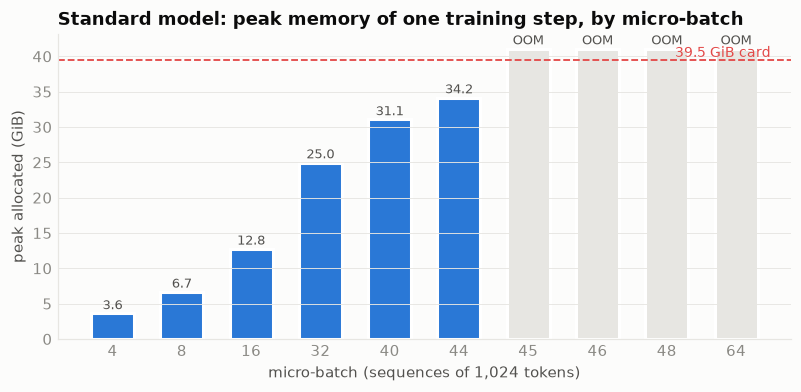

In [4]:
if CUDA and mb['trials']:
    tr = sorted((int(b), p) for b, p in mb['trials'].items())
    fig, ax = plt.subplots(figsize=(8.6, 3.6))
    xs = np.arange(len(tr))
    ax.bar(xs, [p / GiB if p else cap * 1.04 for _, p in tr], width=0.62,
           color=[viz.COLOR['standard'] if p else '#e7e6e2' for _, p in tr], edgecolor='white', linewidth=2)
    for x, (b, p) in zip(xs, tr):
        ax.text(x, (p / GiB if p else cap * 1.04) + 0.6, f'{p/GiB:.1f}' if p else 'OOM', ha='center', fontsize=8.5, color=viz.INK2)
    ax.axhline(cap, color=viz.SLOTS[7], lw=1.2, ls='--'); ax.text(len(tr) - 0.5, cap + 0.4, f'{cap:.1f} GiB card', ha='right', color=viz.SLOTS[7], fontsize=9)
    ax.set_xticks(xs, [b for b, _ in tr]); ax.set_xlabel('micro-batch (sequences of 1,024 tokens)'); ax.set_ylabel('peak allocated (GiB)')
    ax.set_title('Standard model: peak memory of one training step, by micro-batch'); ax.grid(axis='x', visible=False)
    viz.save(fig, '01_batch_search'); plt.show()

## 3 · Train: standard, then activation checkpointing on the same tokens

Recipe shared by every run: AdamW (β = 0.9, 0.95), peak learning rate 2e-3, 5% warmup, cosine to 10%, gradient clipping at 1.0, bf16 autocast with an fp32 residual stream.

Dropout is 0 and weight decay is 0 in **every** run, baseline included. Reversibility needs a deterministic forward pass (lesson §16), and the class asked for weight decay to be off too. Holding both at 0 everywhere means the only thing that differs between runs is how the residual stream is computed and stored.

In [5]:
TOK = CFG['tokens']
baseline = store.cached('run_baseline', lambda: run(dict(B0, name='baseline', mode='standard', batch=FIXED_B, tokens=TOK)))
ckpt     = store.cached('run_ckpt',     lambda: run(dict(B0, name='ckpt',     mode='ckpt',     batch=FIXED_B, tokens=TOK)))
from s13 import report
report.table([baseline, ckpt])

[cache] run_baseline: loaded from full/run_baseline.json
[cache] run_ckpt: loaded from full/run_ckpt.json


,what,batch (seq),tokens/step,steps,final val loss,final train loss,tokens/s,peak mem (GiB),wall (s),cost ($)
run,,,,,,,,,,
baseline,standard (stores activations),32,32768,1525,4.4480,4.3943,199981,24.96,265,0.155
ckpt,activation checkpointing,32,32768,1525,4.4486,4.3938,170371,19.56,308,0.180


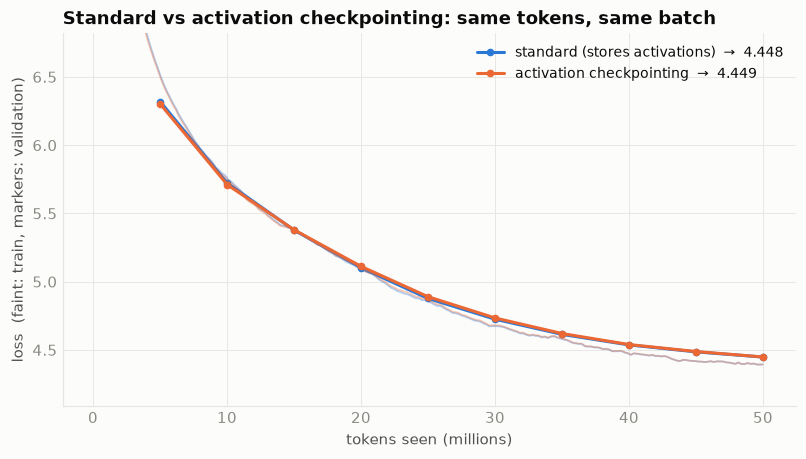

In [6]:
fig, ax = plt.subplots(figsize=(8.6, 4.4))
report.curves([baseline, ckpt], 'Standard vs activation checkpointing: same tokens, same batch', ax=ax)
ax.set_ylim(top=min(7.5, max(baseline['evals']['val']) + 0.5))
viz.save(fig, '01_baseline_curves'); plt.show()

In [7]:
def ratio(a, b, k): return a[k] / b[k]
print(f"checkpointing vs standard:  loss Δ {ckpt['final_val'] - baseline['final_val']:+.4f}   "
      f"speed x{ratio(ckpt, baseline, 'tok_per_s'):.2f}   peak memory x{ratio(ckpt, baseline, 'peak_mem_bytes'):.2f}")
for s in baseline.get('samples', []):
    print('\n—', s.replace('\n', ' '))

checkpointing vs standard:  loss Δ +0.0006   speed x0.85   peak memory x0.78

— The most important thing about learning is to be able to be at a very small scale, with a relatively large scale of time, making it easier to use. - To create a way of learning from a different perspective. - For the first time, it is important

— In the year 1850, we have spent the last six months to work on a similar study. The project has been supported by one of the most important aspects of the research. The project was developed to learn the different types of the project and to create research for the


### What this establishes

* **The fixed batch** is set by measured memory, not a guess, and it is saved to `results/full/fixed_batch.json` for notebooks 02 and 03.
* **Checkpointing is the honest reference point.** It is the standard way to trade compute for memory: store each block's *input*, recompute the inside. Its loss should match the baseline to the run-to-run noise level, because it computes exactly the same function. The price is the extra forward pass, visible in tokens/s.
* The reversible runs in notebook 02 have to beat checkpointing on memory, not just the baseline, to be worth their constraints.